# Clustering — Mall_Customers.csv

Goal: group mall customers into segments using unsupervised clustering
algorithms, compare them with the Silhouette Score, and record the best one.

We report two views per algorithm:
- **auto**: k (or eps/min_samples) searched to maximize silhouette score
- **k=5 (fixed)**: the classic, business-interpretable 5-segment view
  commonly used for this dataset (low/high income x low/high spend, etc.)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

RESULTS_PATH = Path("../results/results_summary.csv")
DATASET_NAME = "Mall_Customers.csv"
TASK = "Clustering"
FIXED_K = 5

## 1. Load & explore

In [2]:
df = pd.read_csv("../Mall_Customers.csv")
print(df.shape)
df.head()

(200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [4]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## 2. Preprocessing
Features used: Age, Annual Income (k$), Spending Score (1-100), and encoded Genre.
All features are scaled since clustering is distance-based.

In [5]:
data = df.copy()
le = LabelEncoder()
data["Genre"] = le.fit_transform(data["Genre"])  # Male/Female -> 1/0

features = ["Genre", "Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = data[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 3. Train multiple clustering algorithms
For algorithms with a `k` / cluster-count hyperparameter, we run two modes:
- search k in [2, 10] and keep whatever maximizes silhouette ("auto")
- force k=5 ("fixed"), the standard interpretable segmentation for this data

In [6]:
def run_kmeans(k):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    return {"score": score, "k": k, "labels": labels, "model": model}


def best_kmeans():
    runs = [run_kmeans(k) for k in range(2, 11)]
    return max(runs, key=lambda r: r["score"])


def run_agglomerative(k):
    model = AgglomerativeClustering(n_clusters=k)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    return {"score": score, "k": k, "labels": labels, "model": model}


def best_agglomerative():
    runs = [run_agglomerative(k) for k in range(2, 11)]
    return max(runs, key=lambda r: r["score"])


def run_gmm(k):
    model = GaussianMixture(n_components=k, random_state=42)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    return {"score": score, "k": k, "labels": labels, "model": model}


def best_gmm():
    runs = [run_gmm(k) for k in range(2, 11)]
    return max(runs, key=lambda r: r["score"])


def best_dbscan(max_noise_fraction=0.25, target_clusters=None):
    # DBSCAN labels sparse points as noise (-1) and silhouette is computed only
    # on the remaining points. If too much of the data is thrown away as noise,
    # the score is not comparable to algorithms that cluster every point (e.g.
    # 2 tiny dense clusters out of 200 points can "fake" a high silhouette) —
    # so we require it to actually cluster most of the dataset to be eligible.
    # If target_clusters is set, only configs producing exactly that many
    # clusters are considered (used for the "k=5 fixed" comparison row).
    best = {"score": -1}
    for eps in np.arange(0.3, 2.1, 0.1):
        for min_samples in range(3, 10):
            model = DBSCAN(eps=eps, min_samples=min_samples)
            labels = model.fit_predict(X_scaled)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            if n_clusters < 2:
                continue
            if target_clusters is not None and n_clusters != target_clusters:
                continue
            mask = labels != -1
            noise_fraction = 1 - (mask.sum() / len(labels))
            if mask.sum() < 2 or noise_fraction > max_noise_fraction:
                continue
            try:
                score = silhouette_score(X_scaled[mask], labels[mask])
            except ValueError:
                continue
            if score > best["score"]:
                best = {"score": score, "eps": round(eps, 2), "min_samples": min_samples,
                        "labels": labels, "model": model, "n_clusters": n_clusters,
                        "noise_fraction": round(noise_fraction, 3)}
    return best


# auto (silhouette-maximizing) runs
km_auto = best_kmeans()
agg_auto = best_agglomerative()
db_auto = best_dbscan()
gmm_auto = best_gmm()

# fixed k=5 runs (DBSCAN has no direct k, so we search for a config that
# happens to produce exactly 5 clusters; if none exists, we note that)
km_fixed = run_kmeans(FIXED_K)
agg_fixed = run_agglomerative(FIXED_K)
gmm_fixed = run_gmm(FIXED_K)
db_fixed = best_dbscan(target_clusters=FIXED_K)

print("=== auto (silhouette-maximizing) ===")
print("KMeans         :", km_auto["score"], "k=", km_auto["k"])
print("Agglomerative  :", agg_auto["score"], "k=", agg_auto["k"])
print("DBSCAN         :", db_auto["score"], "eps=", db_auto.get("eps"),
      "min_samples=", db_auto.get("min_samples"), "noise_fraction=", db_auto.get("noise_fraction"))
print("GaussianMixture:", gmm_auto["score"], "k=", gmm_auto["k"])

print(f"\n=== fixed k={FIXED_K} ===")
print("KMeans         :", km_fixed["score"])
print("Agglomerative  :", agg_fixed["score"])
print("DBSCAN         :", db_fixed.get("score", "no config found with exactly 5 clusters"))
print("GaussianMixture:", gmm_fixed["score"])

=== auto (silhouette-maximizing) ===
KMeans         : 0.42076374869477745 k= 10
Agglomerative  : 0.4176254448686808 k= 10
DBSCAN         : 0.47461124553993045 eps= 0.5 min_samples= 3 noise_fraction= 0.245
GaussianMixture: 0.3972341590494882 k= 10

=== fixed k=5 ===
KMeans         : 0.3040600988258827
Agglomerative  : 0.28699413201651747
DBSCAN         : 0.29628742907379113
GaussianMixture: 0.22164014854021982


## 4. Visualize best overall model's clusters (Annual Income vs Spending Score)

Best algorithm overall (auto): DBSCAN (silhouette=0.4746)


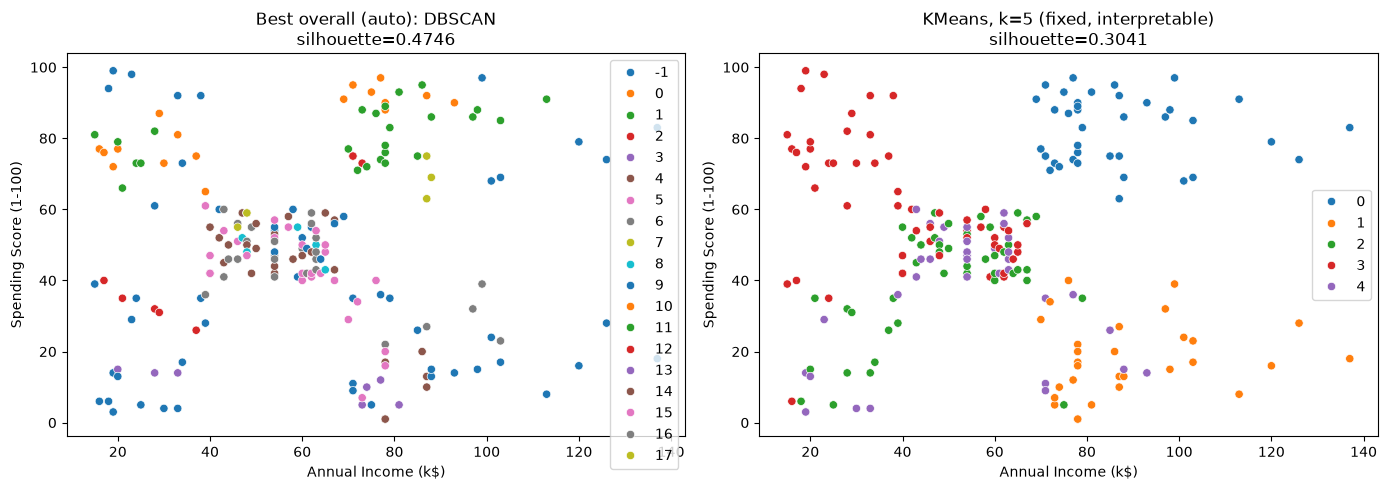

In [7]:
all_runs = {"KMeans": km_auto, "Agglomerative": agg_auto, "DBSCAN": db_auto, "GaussianMixture": gmm_auto}
best_name = max(all_runs, key=lambda name: all_runs[name]["score"])
best_run = all_runs[best_name]
print(f"Best algorithm overall (auto): {best_name} (silhouette={best_run['score']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(
    x=data["Annual Income (k$)"], y=data["Spending Score (1-100)"],
    hue=best_run["labels"], palette="tab10", legend="full", ax=axes[0]
)
axes[0].set_title(f"Best overall (auto): {best_name}\nsilhouette={best_run['score']:.4f}")

sns.scatterplot(
    x=data["Annual Income (k$)"], y=data["Spending Score (1-100)"],
    hue=km_fixed["labels"], palette="tab10", legend="full", ax=axes[1]
)
axes[1].set_title(f"KMeans, k=5 (fixed, interpretable)\nsilhouette={km_fixed['score']:.4f}")

plt.tight_layout()
plt.savefig("../results/clustering_best_plot.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Record results

In [8]:
rows = [
    {"Dataset": DATASET_NAME, "Task": TASK, "Algorithm": "KMeans", "Metric": "Silhouette",
     "Score": round(km_auto["score"], 4), "Params": f"k={km_auto['k']} (auto)"},
    {"Dataset": DATASET_NAME, "Task": TASK, "Algorithm": "KMeans", "Metric": "Silhouette",
     "Score": round(km_fixed["score"], 4), "Params": f"k={FIXED_K} (fixed)"},
    {"Dataset": DATASET_NAME, "Task": TASK, "Algorithm": "Agglomerative", "Metric": "Silhouette",
     "Score": round(agg_auto["score"], 4), "Params": f"k={agg_auto['k']} (auto)"},
    {"Dataset": DATASET_NAME, "Task": TASK, "Algorithm": "Agglomerative", "Metric": "Silhouette",
     "Score": round(agg_fixed["score"], 4), "Params": f"k={FIXED_K} (fixed)"},
    {"Dataset": DATASET_NAME, "Task": TASK, "Algorithm": "DBSCAN", "Metric": "Silhouette",
     "Score": round(db_auto["score"], 4),
     "Params": f"eps={db_auto.get('eps')}, min_samples={db_auto.get('min_samples')}, "
               f"noise_frac={db_auto.get('noise_fraction')} (auto)"},
    {"Dataset": DATASET_NAME, "Task": TASK, "Algorithm": "DBSCAN", "Metric": "Silhouette",
     "Score": round(db_fixed["score"], 4) if "score" in db_fixed and db_fixed["score"] != -1 else None,
     "Params": (f"eps={db_fixed.get('eps')}, min_samples={db_fixed.get('min_samples')}, "
                f"noise_frac={db_fixed.get('noise_fraction')} (k=5 fixed)"
                if db_fixed.get("score", -1) != -1 else "no config found with exactly 5 clusters")},
    {"Dataset": DATASET_NAME, "Task": TASK, "Algorithm": "GaussianMixture", "Metric": "Silhouette",
     "Score": round(gmm_auto["score"], 4), "Params": f"k={gmm_auto['k']} (auto)"},
    {"Dataset": DATASET_NAME, "Task": TASK, "Algorithm": "GaussianMixture", "Metric": "Silhouette",
     "Score": round(gmm_fixed["score"], 4), "Params": f"k={FIXED_K} (fixed)"},
]
results_df = pd.DataFrame(rows)
results_df["Best"] = (results_df["Algorithm"] == best_name) & (
    results_df["Params"].str.contains("(auto)", regex=False)
)
print(results_df.to_string(index=False))

           Dataset       Task       Algorithm     Metric  Score                                              Params  Best
Mall_Customers.csv Clustering          KMeans Silhouette 0.4208                                         k=10 (auto) False
Mall_Customers.csv Clustering          KMeans Silhouette 0.3041                                         k=5 (fixed) False
Mall_Customers.csv Clustering   Agglomerative Silhouette 0.4176                                         k=10 (auto) False
Mall_Customers.csv Clustering   Agglomerative Silhouette 0.2870                                         k=5 (fixed) False
Mall_Customers.csv Clustering          DBSCAN Silhouette 0.4746     eps=0.5, min_samples=3, noise_frac=0.245 (auto)  True
Mall_Customers.csv Clustering          DBSCAN Silhouette 0.2963 eps=0.8, min_samples=7, noise_frac=0.21 (k=5 fixed) False
Mall_Customers.csv Clustering GaussianMixture Silhouette 0.3972                                         k=10 (auto) False
Mall_Customers.csv Clust

In [9]:
RESULTS_PATH.parent.mkdir(exist_ok=True)
if RESULTS_PATH.exists():
    existing = pd.read_csv(RESULTS_PATH)
    existing = existing[existing["Dataset"] != DATASET_NAME]
    combined = pd.concat([existing, results_df], ignore_index=True)
else:
    combined = results_df
combined.to_csv(RESULTS_PATH, index=False)
print(f"Saved to {RESULTS_PATH.resolve()}")

Saved to /home/ayush/ML-assignment-2/results/results_summary.csv
